# 1. Cointegration: when two prices are tied together

A stock price is close to a random walk: it has no level to return to, so it cannot be predicted from its past. Two prices are **cointegrated** when some combination of them *does* return to a level:

$$s_t = \log Y_t - \beta \log X_t - \alpha \quad \text{is stationary.}$$

The spread $s_t$ is then predictable, which is what pairs trading tries to exploit. This notebook covers how to test for cointegration, why correlation is not enough, and how reliable the test is on real stocks.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pairs` package importable from the notebooks folder

from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pairs import (Rule, Settings, benjamini_hochberg, candidate_pairs, engle_granger, kalman_hedge, load_prices, metrics,
                   positions_from_zscore, run_backtest, scan_pairs, sector_of, simulate_pair, split_benchmark, trade_pair)
from pairs.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

prices, benchmark = split_benchmark(load_prices("../data/prices.csv"))
log_prices = np.log(prices)
print(f"{prices.shape[1]} stocks, {len(prices):,} trading days, {prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}")

104 stocks, 4,243 trading days, 2010-01-04 to 2026-11-13


## 1.1 Correlation is not cointegration

Two series built from simulation, where the truth is known:

* a cointegrated pair, $\log Y = 0.5 + 1.3\,\log X + s$ with a mean-reverting spread $s$;
* two random walks that have nothing to do with each other.

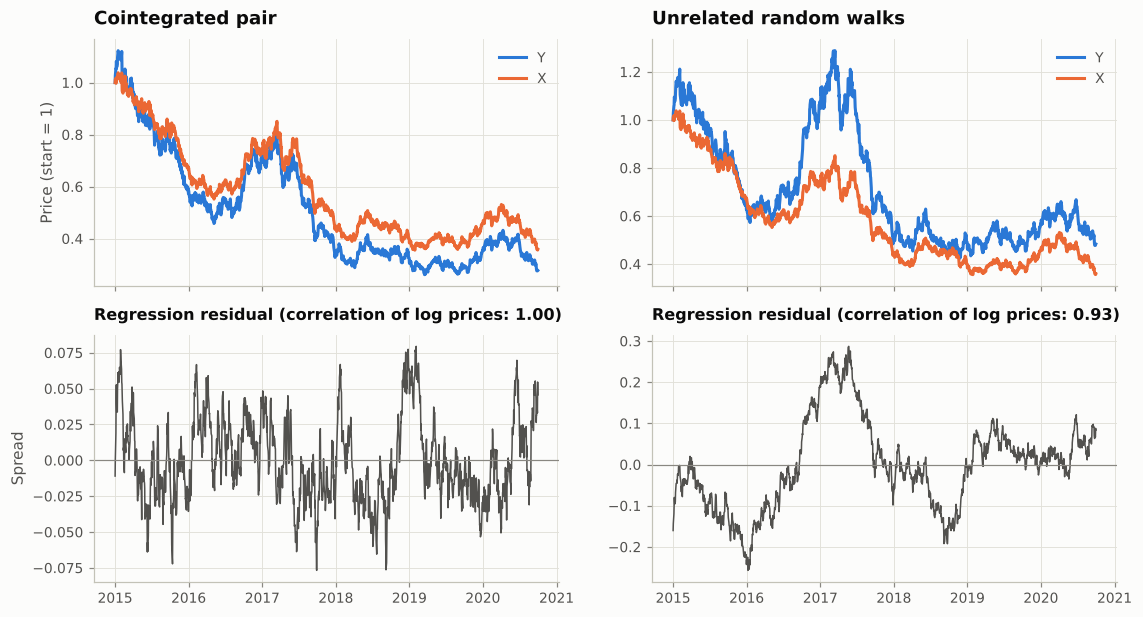

In [2]:
tied = simulate_pair(n_days=1500, beta=1.3, half_life=15, cointegrated=True, seed=1)
loose = simulate_pair(n_days=1500, cointegrated=False, seed=1)

fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True)
for column, (pair, title) in enumerate([(tied, "Cointegrated pair"), (loose, "Unrelated random walks")]):
    logs = np.log(pair)
    slope, intercept = np.polyfit(logs["X"], logs["Y"], 1)
    spread = logs["Y"] - slope * logs["X"] - intercept
    axes[0, column].plot(pair.index, pair["Y"] / pair["Y"].iloc[0], color=BLUE, label="Y")
    axes[0, column].plot(pair.index, pair["X"] / pair["X"].iloc[0], color=ORANGE, label="X")
    axes[0, column].set_title(title); axes[0, column].legend()
    axes[1, column].plot(pair.index, spread, color=INK_SOFT, linewidth=1.0)
    axes[1, column].axhline(0, color=MUTED, linewidth=0.8)
    correlation = np.corrcoef(logs["Y"], logs["X"])[0, 1]
    axes[1, column].set_title(f"Regression residual (correlation of log prices: {correlation:.2f})", fontsize=10.5)
axes[0, 0].set_ylabel("Price (start = 1)"); axes[1, 0].set_ylabel("Spread");

Both pairs of log prices are highly correlated in levels, because any two trending series are. This is the *spurious regression* problem. What separates them is the residual: on the left it keeps crossing zero, on the right it wanders.

## 1.2 The Engle-Granger test

1. Regress $\log Y$ on $\log X$ to get $\beta$ and the residual spread.
2. Test whether the spread is stationary with an augmented Dickey-Fuller regression, $\Delta s_t = \gamma\,s_{t-1} + \varphi\,\Delta s_{t-1} + \varepsilon_t$. A random walk has $\gamma = 0$; mean reversion means $\gamma < 0$.

The statistic is $\gamma$ divided by its standard error. Its distribution is not the usual Student one, and because the regression already picked the most stationary-looking combination, special critical values (MacKinnon) are needed.

In [3]:
rows = []
for name, pair in [("Cointegrated pair", tied), ("Unrelated random walks", loose)]:
    result = engle_granger(np.log(pair["Y"].to_numpy()), np.log(pair["X"].to_numpy()))
    rows.append({"Series": name, "Hedge ratio": result.beta, "ADF statistic": result.t_stat, "p-value": result.p_value,
                 "Half-life (days)": result.half_life})
pd.DataFrame(rows).set_index("Series")

,Hedge ratio,ADF statistic,p-value,Half-life (days)
Series,,,,
Cointegrated pair,1.306,-5.976,0.000,14.617
Unrelated random walks,0.948,-2.085,0.484,123.713


The test recovers the true hedge ratio (1.3) and half-life (15 days) of the first pair and does not reject for the second.

The **half-life** comes from an AR(1) fit of the spread, $s_t - s_{t-1} = a + b\,s_{t-1} + \varepsilon_t$: a deviation shrinks by a factor $(1+b)$ a day and halves after $-\ln 2 / \ln(1+b)$ days. It says how long a trade is expected to last.

**How often is the test wrong?** On pairs of independent random walks it should reject 5% of the time. The scan used later in the project runs the regression in both directions and keeps the better result, which raises that rate:

In [4]:
rng = np.random.default_rng(0)
walks = np.cumsum(0.015 * rng.standard_normal((504, 4000)), axis=0)
one_way, best_of_two = [], []
for i in range(2000):
    a, b = walks[:, 2 * i], walks[:, 2 * i + 1]
    forward, backward = engle_granger(a, b).p_value, engle_granger(b, a).p_value
    one_way.append(forward <= 0.05); best_of_two.append(min(forward, backward) <= 0.05)
print(f"False positives at the 5% level, one direction:      {np.mean(one_way):.1%}")
print(f"False positives at the 5% level, better of two:      {np.mean(best_of_two):.1%}")

False positives at the 5% level, one direction:      5.5%
False positives at the 5% level, better of two:      9.2%


## 1.3 A real pair

Visa and Mastercard: same business, same customers, same regulation.

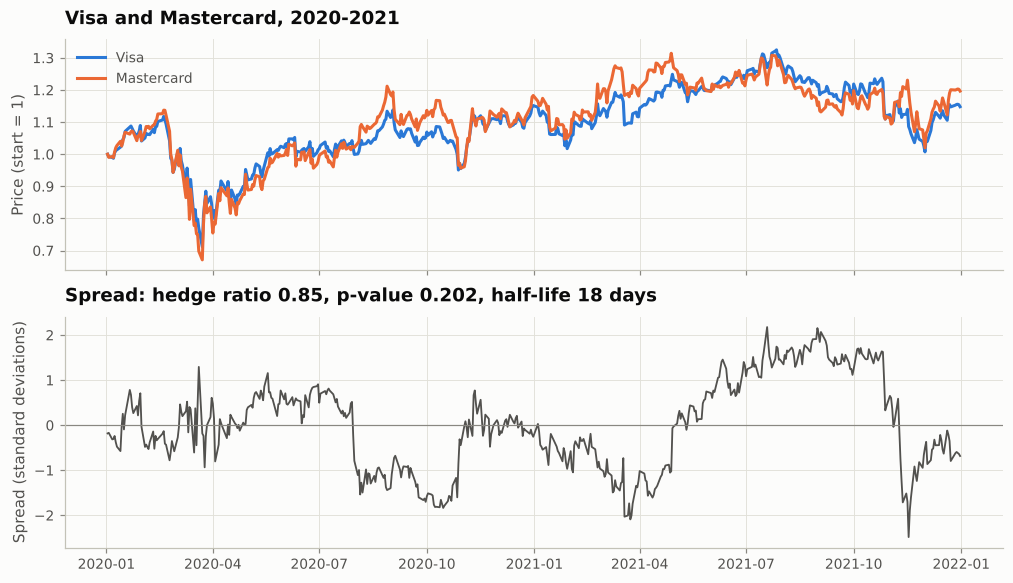

In [5]:
window = prices[["V", "MA"]].loc["2020":"2021"]
result = engle_granger(np.log(window["V"].to_numpy()), np.log(window["MA"].to_numpy()))
spread = np.log(window["V"]) - result.beta * np.log(window["MA"]) - result.alpha

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
top.plot(window.index, window["V"] / window["V"].iloc[0], color=BLUE, label="Visa")
top.plot(window.index, window["MA"] / window["MA"].iloc[0], color=ORANGE, label="Mastercard")
top.set_ylabel("Price (start = 1)"); top.set_title("Visa and Mastercard, 2020-2021"); top.legend()
bottom.plot(spread.index, spread / spread.std(), color=INK_SOFT, linewidth=1.2)
bottom.axhline(0, color=MUTED, linewidth=0.8)
bottom.set_ylabel("Spread (standard deviations)")
bottom.set_title(f"Spread: hedge ratio {result.beta:.2f}, p-value {result.p_value:.3f}, half-life {result.half_life:.0f} days");

Even this textbook pair is not significant at the 5% level over these two years. The spread does revert, but two years contain only a few complete swings, and the test has little power against slow mean reversion.

## 1.4 Testing every pair: the multiple-testing problem

There are 567 pairs of stocks within the same sector. Testing all of them at the 5% level produces dozens of "discoveries" even if no pair is cointegrated.

In [6]:
pairs = candidate_pairs(prices.columns, same_sector=True)
window = 504
scans = []
for start in range(0, len(prices) - window + 1, window):
    scan = scan_pairs(log_prices.iloc[start:start + window], pairs)
    scan["window"] = f"{prices.index[start]:%Y}-{prices.index[start + window - 1]:%Y}"
    scans.append(scan)

chance = np.mean(best_of_two) * len(pairs)
counts = pd.DataFrame({
    "Pairs tested": [len(s) for s in scans],
    "p < 5%": [int((s["p_value"] <= 0.05).sum()) for s in scans],
    "Expected by chance": [round(chance)] * len(scans),
    "After Benjamini-Hochberg": [int(benjamini_hochberg(s["p_value"]).sum()) for s in scans],
}, index=[s["window"].iloc[0] for s in scans])
counts

,Pairs tested,p < 5%,Expected by chance,After Benjamini-Hochberg
2010-2011,567,44,52,0
2012-2014,567,50,52,0
2014-2016,567,102,52,0
2016-2018,567,69,52,1
2018-2020,567,61,52,0
2020-2022,567,102,52,3
2022-2024,567,97,52,0
2024-2026,567,66,52,0


The number of pairs passing the test is of the same order as what chance alone produces. The **Benjamini-Hochberg** procedure controls the share of false discoveries among the pairs that are kept: it sorts the $m$ p-values and keeps the $k$ smallest, where $k$ is the largest rank with $p_{(k)} \le \tfrac{k}{m}\times 5\%$. Almost nothing survives.

That does not prove no pair is cointegrated, only that the test cannot single them out among 567 candidates with two years of data.

## 1.5 Does cointegration persist?

The decisive check is out of sample. If a pair that tests as cointegrated in one window is truly tied together, it should test as cointegrated again in the next window far more often than a pair taken at random.

In [7]:
rows = []
for k in range(len(scans) - 1):
    scan = scans[k]
    following = log_prices.iloc[(k + 1) * window:(k + 2) * window]
    later = pd.DataFrame([vars(engle_granger(following[y].to_numpy(), following[x].to_numpy()))
                          for y, x in zip(scan["y"], scan["x"])])
    selected = (scan["p_value"] <= 0.05).to_numpy()
    rows.append({"Window": scan["window"].iloc[0], "Pairs with p < 5%": int(selected.sum()),
                 "of which p < 5% in the next window": (later.loc[selected, "p_value"] <= 0.05).mean(),
                 "All pairs: p < 5% in the next window": (later["p_value"] <= 0.05).mean(),
                 "Rank correlation of the statistics": scan["t_stat"].corr(later["t_stat"], method="spearman")})
persistence = pd.DataFrame(rows).set_index("Window")
persistence.style.format({"of which p < 5% in the next window": "{:.0%}", "All pairs: p < 5% in the next window": "{:.0%}",
                          "Rank correlation of the statistics": "{:.2f}"})

,Pairs with p < 5%,of which p < 5% in the next window,All pairs: p < 5% in the next window,Rank correlation of the statistics
Window,,,,
2010-2011,44,0%,6%,-0.07
2012-2014,50,18%,15%,0.05
2014-2016,102,15%,9%,-0.03
2016-2018,69,3%,4%,0.00
2018-2020,61,10%,13%,0.01
2020-2022,102,9%,7%,0.01
2022-2024,97,4%,7%,-0.06


In [8]:
selected_rate = np.average(persistence["of which p < 5% in the next window"], weights=persistence["Pairs with p < 5%"])
print(f"Pairs significant in one window that are significant in the next: {selected_rate:.0%}")
print(f"Any pair, significant in the next window:                         {persistence['All pairs: p < 5% in the next window'].mean():.0%}")
print(f"Average rank correlation of the test statistic between windows:   {persistence['Rank correlation of the statistics'].mean():.2f}")

Pairs significant in one window that are significant in the next: 9%
Any pair, significant in the next window:                         9%
Average rank correlation of the test statistic between windows:   -0.01


A pair that passes the test in one window is about as likely as any other pair to pass it in the next, and the ranking of pairs by test statistic in one window says nothing about the ranking in the next (rank correlation close to zero).

## Summary

* Cointegration is about the *residual* of the relation between two prices, not about their correlation.
* The Engle-Granger test works on simulated data, where it recovers the hedge ratio and the half-life.
* Applied to 567 real pairs, it flags about as many pairs as chance would, and the pairs it flags do not stay cointegrated. On this universe and with two-year windows, in-sample cointegration is mostly a statistical accident.
* This already predicts the outcome of the backtest in notebook 3.